# Semana 14 — Codificación, decodificación y validación cruzada

**Objetivo:** construir un decodificador que lea el estímulo desde la actividad de una población,
evaluándolo solo con datos no usados en su ajuste.

## Codificación (estímulo → respuesta)

Cuatro neuronas con curvas de sintonía gaussianas centradas en $x_n^*$:

$$\lambda_n(x) = \exp\!\big(1 - \kappa\,(x - x_n^*)^2\big), \qquad y_n \sim \text{Poisson}(\lambda_n(x))$$

con $x_n^* \in \{-0.7, -0.2, 0.25, 0.65\}$ y $\kappa = 5$.

## Decodificación (respuesta → estímulo)

Decodificador lineal: $\hat x = w_0 + \sum_n w_n y_n$, ajustado por mínimos cuadrados.

**Validación cruzada de 5 particiones:** se divide en 5 grupos; cada grupo se predice con un
modelo ajustado en los otros 4. Así cada predicción es *fuera de muestra*. Línea base: predecir
siempre la media del estímulo en entrenamiento.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience import fit_linear_model
from computational_neuroscience.outputs import save_data, save_figure

WEEK = 14
TRIALS = 300
PREFERRED = np.array([-0.7, -0.2, 0.25, 0.65])
SENSITIVITY = 5.0
rng = np.random.default_rng(14)


def tuning(stimulus: np.ndarray) -> np.ndarray:
    return np.exp(1.0 - SENSITIVITY * (np.asarray(stimulus)[:, None] - PREFERRED) ** 2)


stimulus = rng.uniform(-1.0, 1.0, TRIALS)
activity = rng.poisson(tuning(stimulus))
folds = np.array_split(rng.permutation(TRIALS), 5)
predictions = np.empty(TRIALS)
baseline_predictions = np.empty(TRIALS)
for test_indices in folds:
    train_mask = np.ones(TRIALS, dtype=bool)
    train_mask[test_indices] = False
    decoder = fit_linear_model(activity[train_mask], stimulus[train_mask])
    predictions[test_indices] = decoder.predict(activity[test_indices])
    baseline_predictions[test_indices] = stimulus[train_mask].mean()

model_rmse = float(np.sqrt(np.mean((stimulus - predictions) ** 2)))
baseline_rmse = float(np.sqrt(np.mean((stimulus - baseline_predictions) ** 2)))
in_sample = fit_linear_model(activity, stimulus)
in_sample_rmse = float(np.sqrt(np.mean((stimulus - in_sample.predict(activity)) ** 2)))

## Figura

Izquierda: curvas de sintonía (el modelo de codificación). Derecha: estímulo decodificado
fuera de muestra frente al verdadero; la diagonal es la decodificación perfecta.

Saved: weeks/week_14_encoding_decoding/outputs/stimulus_decoder.png
Saved: weeks/week_14_encoding_decoding/outputs/stimulus_decoder.npz


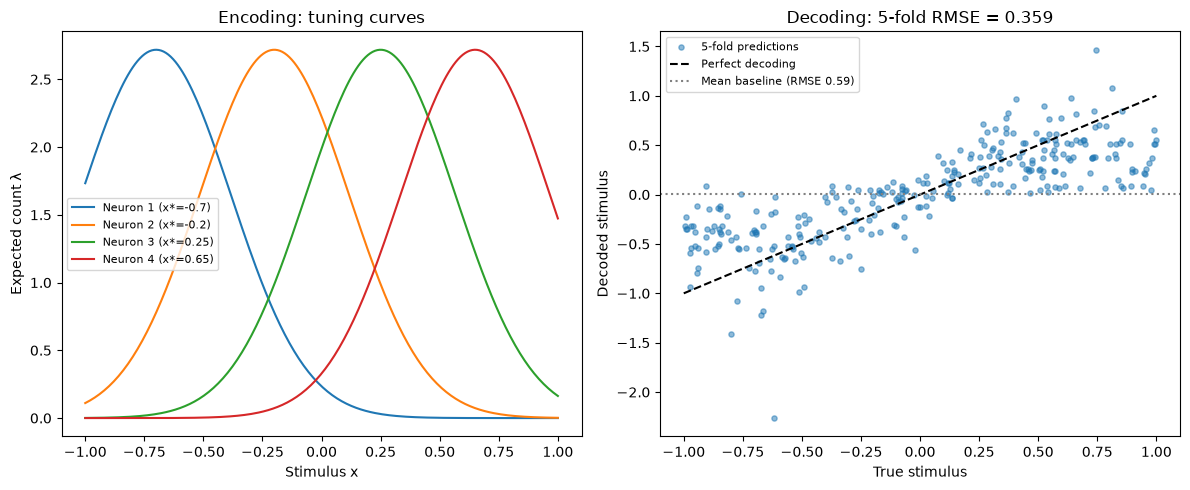

In [2]:
grid = np.linspace(-1.0, 1.0, 200)
figure, axes = plt.subplots(1, 2, figsize=(12, 5))
for index, rate in enumerate(tuning(grid).T):
    axes[0].plot(grid, rate, label=f"Neuron {index + 1} (x*={PREFERRED[index]:g})")
axes[0].set(xlabel="Stimulus x", ylabel="Expected count λ", title="Encoding: tuning curves")
axes[0].legend(fontsize=8)
axes[1].scatter(stimulus, predictions, s=14, alpha=0.5, label="5-fold predictions")
axes[1].plot([-1, 1], [-1, 1], "k--", label="Perfect decoding")
axes[1].axhline(stimulus.mean(), color="grey", linestyle=":", label=f"Mean baseline (RMSE {baseline_rmse:.2f})")
axes[1].set(xlabel="True stimulus", ylabel="Decoded stimulus", title=f"Decoding: 5-fold RMSE = {model_rmse:.3f}")
axes[1].legend(fontsize=8)
save_figure(WEEK, figure, "stimulus_decoder.png")
save_data(WEEK, "stimulus_decoder.npz", stimulus=stimulus, activity=activity, predictions=predictions,
          model_rmse=np.array(model_rmse), baseline_rmse=np.array(baseline_rmse))

## Validación

- Cada ensayo se predice exactamente una vez y nunca con un modelo que lo vio (particiones disjuntas).
- El decodificador supera claramente a la línea base.
- El error fuera de muestra es mayor o igual que el error en muestra (el optimismo del ajuste).
- La línea base tiene RMSE ≈ $\sqrt{1/3} \approx 0.577$, la desviación estándar de $U(-1, 1)$.

In [3]:
all_test = np.concatenate(folds)
assert np.array_equal(np.sort(all_test), np.arange(TRIALS))
assert model_rmse < 0.75 * baseline_rmse
assert model_rmse >= in_sample_rmse
assert abs(baseline_rmse - np.sqrt(1 / 3)) < 0.05
print(f"RMSE: decoder 5-fold {model_rmse:.3f}, in-sample {in_sample_rmse:.3f}, mean baseline {baseline_rmse:.3f}")

RMSE: decoder 5-fold 0.359, in-sample 0.351, mean baseline 0.586


## Interpretación y límites

- En los extremos ($|x| > 0.8$) las predicciones se aplanan: las neuronas apenas responden allí y
  un decodificador lineal no puede extrapolar. Un decodificador bayesiano que use las curvas de
  sintonía lo haría mejor.
- Para evitar fuga de información, cualquier preprocesamiento (normalizar, elegir neuronas)
  debe ajustarse **dentro** de cada partición de entrenamiento.

**Para tu entrega:** añade 4 neuronas más y compara el RMSE fuera de muestra; ¿cuándo deja de mejorar?